# Topic Extraction and Stance Analysis: Workflow Overview

| Item | Description |
|---|---|
| Goal | Guide a reader through the T2 section: how the hearing summaries of T1 became a codebook of 111 topics, how each legislator statement was extracted and placed under a topic, how the topics were checked against human codes, how support and concern are counted over time, and how one hearing can be followed through every step. |
| Covers | The sixteen notebooks of T2.1 to T2.5, their inputs and outputs, where the data live, and how to obtain every input again. |
| Output | None. This notebook runs no step and writes no file. |
| Run | Not applicable. The language-model steps ran in August 2026 and are not rerun. Each notebook states its own run in its header. |

T2 works in two tracks. Track 1 reads the 2,352 hearing summaries and builds the topic map. The model names each hearing's subjects, the phrases are clustered by meaning, and the clusters are labelled and reviewed. 111 topics are frozen as the codebook. Track 2 reads the legislators' own words. Each of the 220,160 non-empty speaking turns goes to the model, which returns the positions it finds. A position carries the sentences that express it, the policy object as a neutral phrase, and support or concern. The 32,385 records are then placed under the nearest codebook topic. A validation compares the topics with the human codes of the Comparative Agendas Project (CAP). The last part counts support and concern by topic group and Congress. The model is Qwen3.5-4B, run locally on one GPU per task; the encoder for every embedding is bge-large-en-v1.5.


## 1. The workflow in one figure


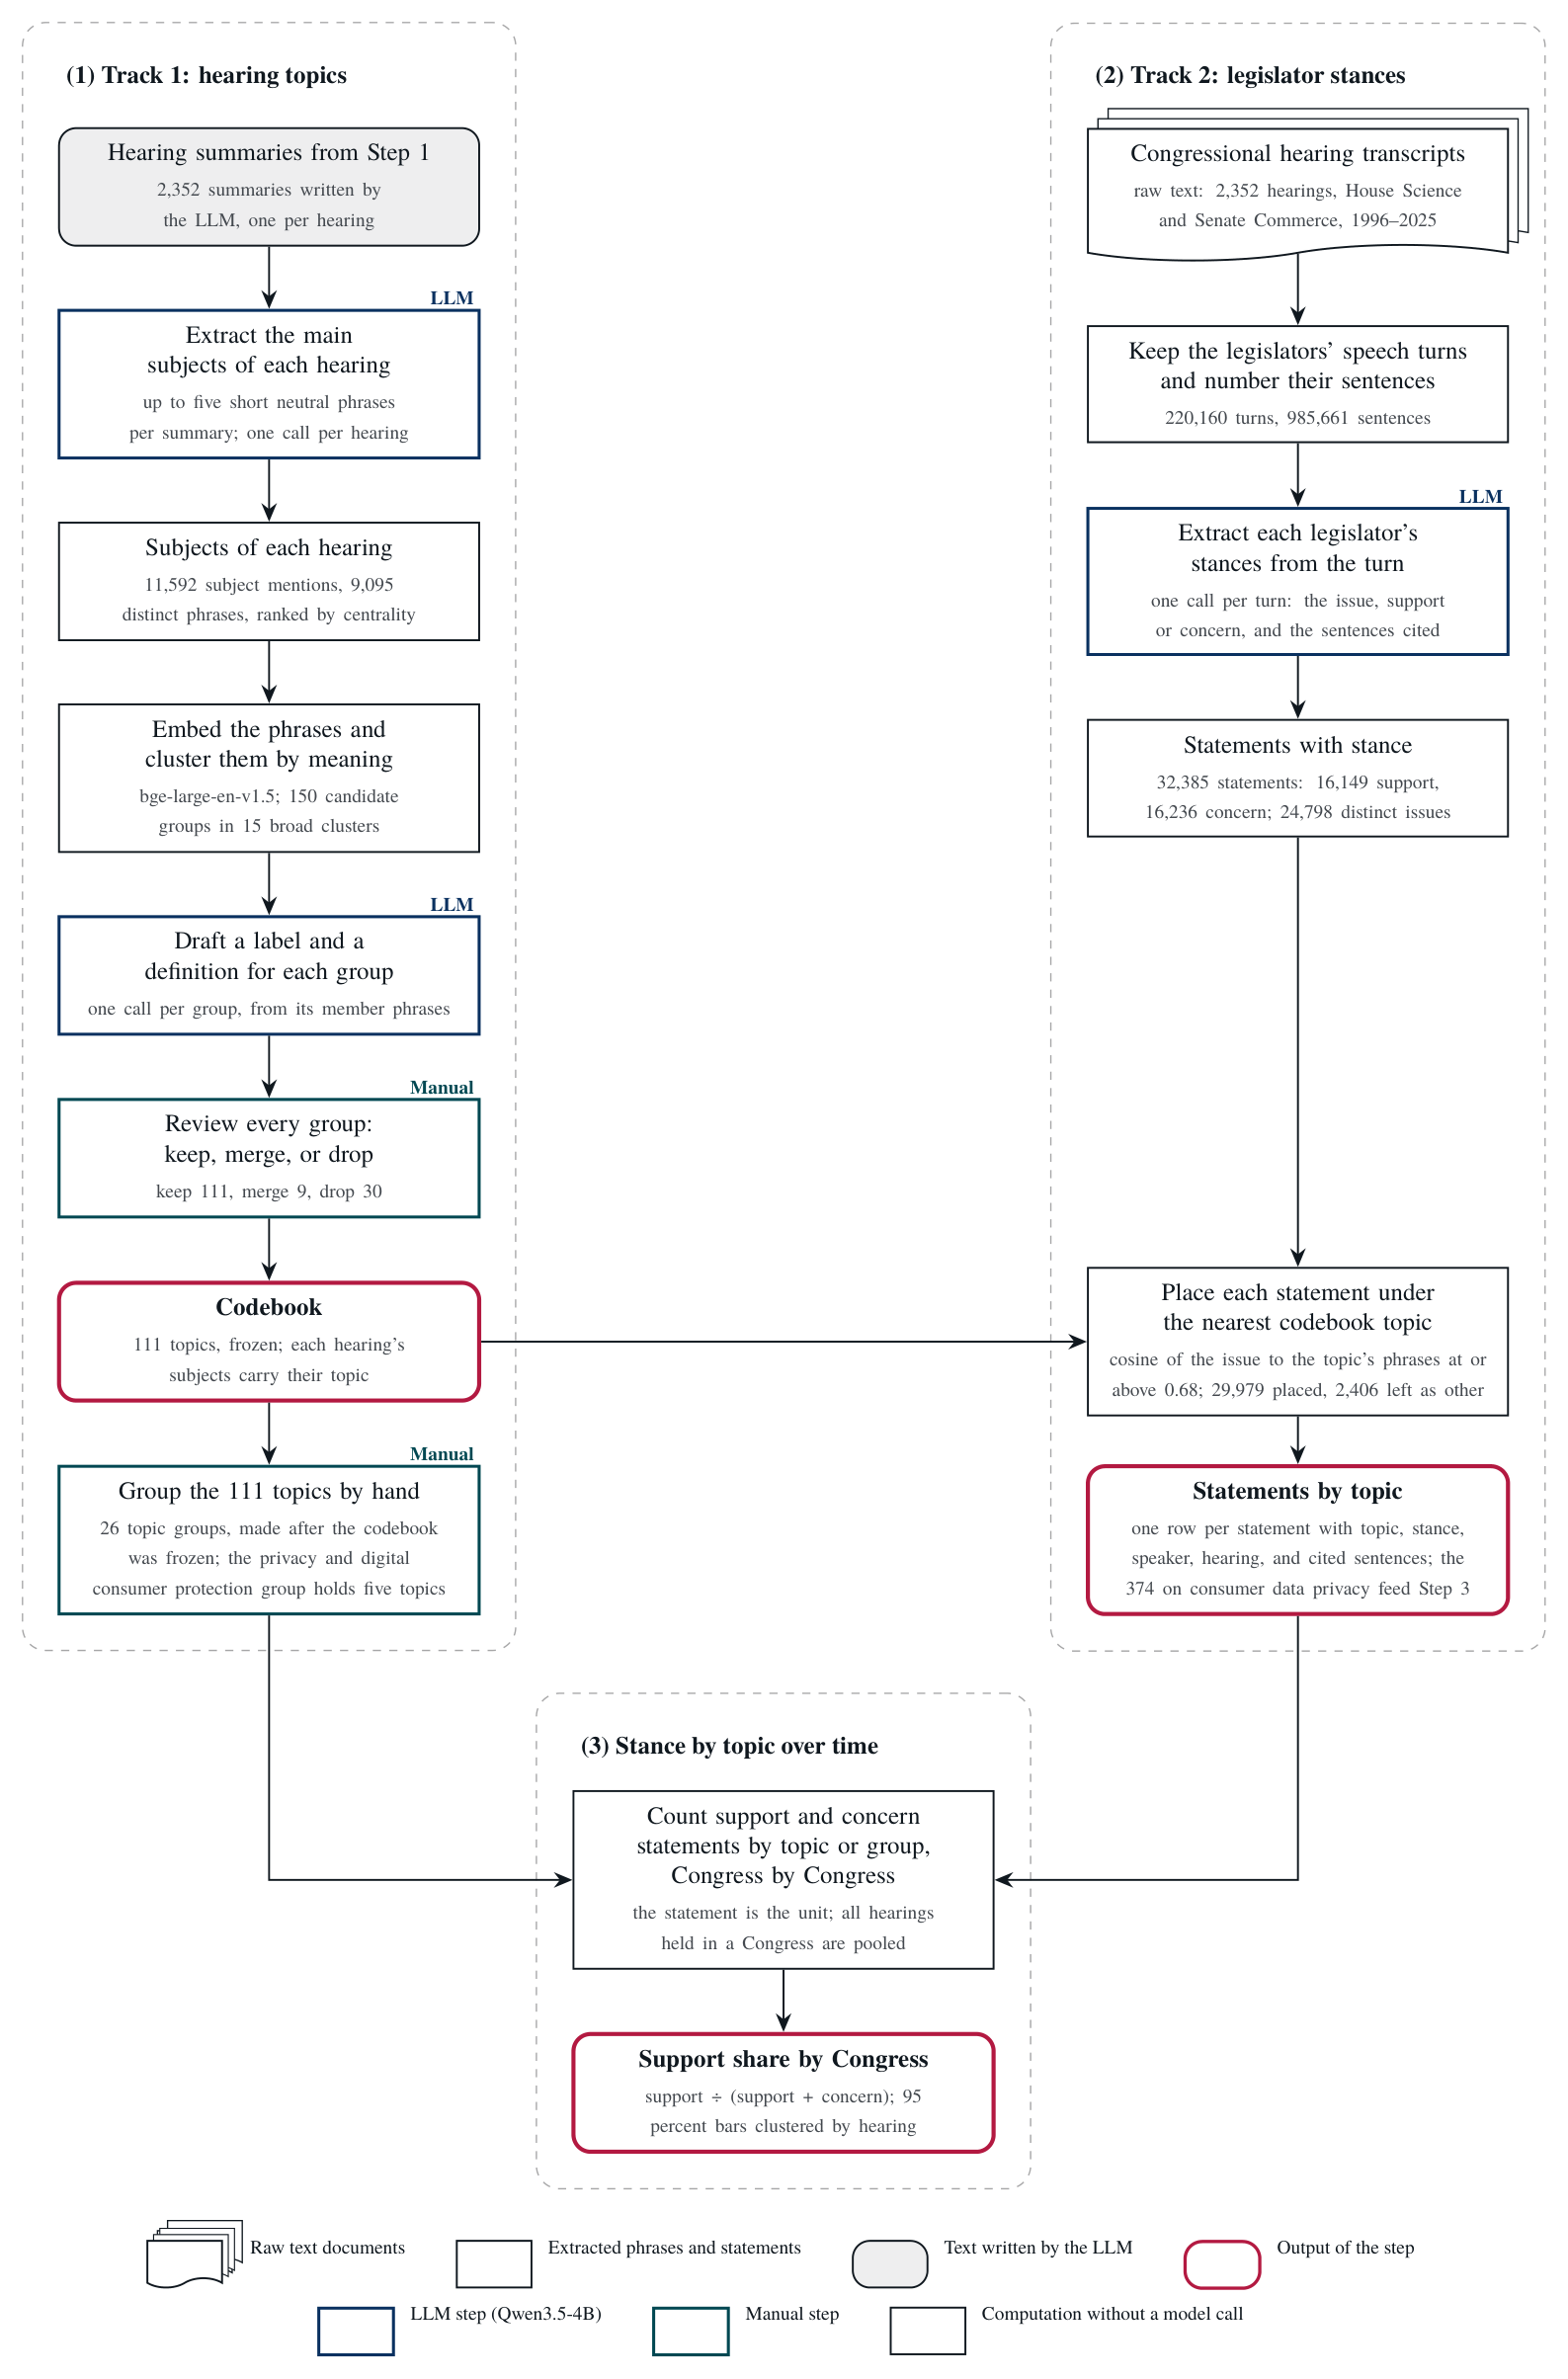

In [1]:
from IPython.display import Image, display

display(Image(filename="../R - Results/figures/T2 - Topic Extraction and Stance Analysis/fig_topic_extraction_flowchart.png", width=900))


## 2. The five parts and their notebooks

**T2.1, Track 1: topic extraction from the hearing summaries.** [T2.1.1 - Production - Extract Topics from Every Summary](T2.1%20-%20Track%201%20-%20Topic%20Extraction%20based%20on%20Hearing%20Summaries/T2.1.1%20-%20Production%20-%20Extract%20Topics%20from%20Every%20Summary.ipynb) asks the model for up to five neutral phrases per summary. [T2.1.2 - Cluster - Embed and Cluster the Topic Phrases](T2.1%20-%20Track%201%20-%20Topic%20Extraction%20based%20on%20Hearing%20Summaries/T2.1.2%20-%20Cluster%20-%20Embed%20and%20Cluster%20the%20Topic%20Phrases.ipynb) embeds the 9,095 distinct phrases and clusters them at nine candidate counts. [T2.1.3 - Draft - Label and Define Each Cluster](T2.1%20-%20Track%201%20-%20Topic%20Extraction%20based%20on%20Hearing%20Summaries/T2.1.3%20-%20Draft%20-%20Label%20and%20Define%20Each%20Cluster.ipynb) has the model draft a label and a definition for each of the 150 clusters. [T2.1.4 - Freeze - Review the Clusters and Freeze the Codebook](T2.1%20-%20Track%201%20-%20Topic%20Extraction%20based%20on%20Hearing%20Summaries/T2.1.4%20-%20Freeze%20-%20Review%20the%20Clusters%20and%20Freeze%20the%20Codebook.ipynb) records the review (keep 111, merge 9, drop 30), freezes the codebook, and assigns each hearing its primary topic. [T2.1.5 - Groups - Group the 111 Topics by Hand](T2.1%20-%20Track%201%20-%20Topic%20Extraction%20based%20on%20Hearing%20Summaries/T2.1.5%20-%20Groups%20-%20Group%20the%20111%20Topics%20by%20Hand.ipynb) records the hand-made grouping of the topics into 26 groups, the upper level the analysis uses.

**T2.2, Track 2: legislator stance extraction.** [T2.2.1 - Prepare - Legislator Turns as Numbered Sentences](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.1%20-%20Prepare%20-%20Legislator%20Turns%20as%20Numbered%20Sentences.ipynb) splits every legislator turn into numbered sentences. [T2.2.2 - Draft - Develop the Stance Prompt on Thirty Turns](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.2%20-%20Draft%20-%20Develop%20the%20Stance%20Prompt%20on%20Thirty%20Turns.ipynb) is the development run of the prompt. [T2.2.3 - Production - Extract Stances from Every Turn in Shards](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.3%20-%20Production%20-%20Extract%20Stances%20from%20Every%20Turn%20in%20Shards.ipynb) is the production run, five GPU shards. [T2.2.4 - Production - Assemble the Stance Records](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.4%20-%20Production%20-%20Assemble%20the%20Stance%20Records.ipynb) combines the shards into one table and checks it. [T2.2.5 - Check - Read Records against Their Sentences](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.5%20-%20Check%20-%20Read%20Records%20against%20Their%20Sentences.ipynb) prints samples next to their cited sentences. [T2.2.6 - Assign - Place Each Statement under a Codebook Topic](T2.2%20-%20Track%202%20-%20Legislator%20Stance%20Extraction/T2.2.6%20-%20Assign%20-%20Place%20Each%20Statement%20under%20a%20Codebook%20Topic.ipynb) places each record under the nearest topic at cosine 0.68 or above.

**T2.3, validation of the topics.** [T2.3.1 - Validation - Match Hearings to CAP Records](T2.3%20-%20Validation%20of%20Topics/T2.3.1%20-%20Validation%20-%20Match%20Hearings%20to%20CAP%20Records.ipynb) links 1,796 hearings to CAP records on metadata only. [T2.3.2 - Validation - Compare the Codebook with CAP Codes](T2.3%20-%20Validation%20of%20Topics/T2.3.2%20-%20Validation%20-%20Compare%20the%20Codebook%20with%20CAP%20Codes.ipynb) cross-tabulates the topic groups against CAP's human-coded major topics and measures the agreement at both levels.

**T2.4, stance by topic over time.** [T2.4.1 - Grouped Stance Volume](T2.4%20-%20Stance%20by%20Topic%20over%20Time/T2.4.1%20-%20Grouped%20Stance%20Volume.ipynb) counts concern and support turns by topic group. [T2.4.2 - Privacy Group Stance over Time](T2.4%20-%20Stance%20by%20Topic%20over%20Time/T2.4.2%20-%20Privacy%20Group%20Stance%20over%20Time.ipynb) draws the support share by Congress for the privacy group. [T2.4.3 - Export Privacy Stance Turns](T2.4%20-%20Stance%20by%20Topic%20over%20Time/T2.4.3%20-%20Export%20Privacy%20Stance%20Turns.ipynb) exports the group's turns with their text. [T2.4.4 - Privacy Topic Stance Volume](T2.4%20-%20Stance%20by%20Topic%20over%20Time/T2.4.4%20-%20Privacy%20Topic%20Stance%20Volume.ipynb) counts by the group's five topics.

**T2.5, the running example.** [T2.5.1 - Example - Topics and Stances in the Facebook Hearing Step by Step](T2.5%20-%20Running%20Example%20%5BFacebook-Cambridge%20Analytica%20Scandal%20Hearing%5D/T2.5.1%20-%20Example%20-%20Topics%20and%20Stances%20in%20the%20Facebook%20Hearing%20Step%20by%20Step.ipynb) follows the Facebook hearing of April 10, 2018 through both tracks and verifies every logged call.


## 3. The upper level of the codebook

The draft of T2.1.3 also clustered the phrases into 15 broad clusters, and the frozen codebook keeps them as `theme_id` and `theme_label`. The review found them too mixed to read. The analysis therefore groups the 111 topics by hand into 26 topic groups (T2.1.5), made from the topic labels and definitions after the freeze. T2.3.2 and T2.4 use the groups. The themes stay in the frozen file for the record only.


## 4. Where the data live

Every notebook reads and writes under the scratch root, `/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/`, in the subfolder of the notebook that produced the file.

| Subfolder | Processed | Interim |
|---|---|---|
| T2.1 | `codebook_v1.parquet`, `track1_assigned.parquet`, `hearing_topics_v1.parquet`, `topic_centroids.npz`, `topic_groups.parquet` | `track1/` (topics and call log), `taxonomy/` (phrases, families, embeddings, consensus, draft) |
| T2.2 | `member_turns.parquet`, `stance_turns.parquet`, `stance_records.parquet`, `track2_assigned.parquet` | `dev/` (development logs), `shards/`, `status/` (production shards and logs) |
| T2.3 | `cap_match.parquet` | the August agreement summary; `Raw/` holds the CAP download and the earlier benchmark labels |
| T2.4 | the privacy-group turn export | the count tables behind the figures |

Figures and tables go to `R - Results/figures` and `R - Results/tables` under the same subfolder names, one folder per notebook. The flowchart above sits at the section level of `R - Results/figures`.


## 5. How to obtain the inputs

**The hearings and their turns.** `hearings_sst.parquet` is built by D1; see the D1 overview. **The summaries.** `hearing_summaries.parquet` is built by T1. **The CAP data.** The US Congressional Hearings dataset (version 21.7) and the master codebook come from the Comparative Agendas Project, comparativeagendas.net. They are under Datasets, United States, Congressional Hearings. Place the CSV and the codebook in `T2.3 - Validation of Topics/Raw/comparative_agenda_project/`. **The models.** Qwen3.5-4B and bge-large-en-v1.5 download from the Hugging Face Hub without a token; the first use writes them to `cache/huggingface`. A token in `.env`, following `.env.example`, is needed only for gated models. **The hardware.** Each language-model step ran on one NVIDIA A40. The Track 2 production run took 42 GPU hours over five shards and is not meant to be repeated.


## 6. How to read a notebook in this section

Every notebook opens with the same table and a Run row that says when it ran and why it is or is not rerun. The notebooks that call the language model (T2.1.1, T2.1.3, T2.2.2, T2.2.3) keep the cell outputs of their August run. T2.2.3 shows the executed copy of shard 0 and ends with a cell that reads the logs of all five shards. The placement notebook T2.2.6 keeps its August output and ends with a cell that reads it back. The notebooks that run on a CPU were rebuilt into scratch copies on 2026-10-31 and found identical to the stored tables. The codebook rebuilt byte for byte. T2.3.2 was rebuilt on 2026-10-31 as a crosswalk against CAP's codes, with the topic groups as the upper level; it needs no GPU. The helper code of the earlier version, the prompts, the sentence rules, and the parsers, is written out inside each notebook that uses it.
